### **Student Information**
GitHub ID: NotCharles-Chen

Kaggle name: Charles0218

Kaggle private scoreboard snapshot:

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

***

# **Project Report**

---

## 1. Model Development (10 pts Required)

**Task.** 4,800 posts (3,360 train / 1,440 test) from several sources — Reddit-style comments with `[NAME]` placeholders, tweets with `@<username>`, and machine-translated news sentences — labelled with one of six emotions: joy 875, anger 674, sadness 628, disgust 454, surprise 441, fear 288. The metric is macro F1, so the rare classes (fear, surprise, disgust) count as much as joy.

**Final result.** A probability-averaging ensemble of fine-tuned transformers: 5-fold out-of-fold (OOF) macro F1 **0.6479**, public leaderboard **PUBLIC_TBD**. A TF-IDF + linear model reaches only ~0.51 in the same cross-validation.

### 1.1 Preprocessing Steps

* **Joining the files.** `final_posts.json` (post_id, text) ⨝ `data_identification.csv` (train/test split) ⨝ `emotion.csv` (labels for train). Checks: no missing text, no duplicated `post_id`, 1,440 test ids identical to `sampleSubmission.csv`.
* **What the text looks like.** Median 13 words, 90th percentile 25, a few posts of several hundred words. 7% of training posts contain `[NAME]`, 3% `@<username>`; there are no URLs or HTML entities to strip.
* **Cleaning for transformers (kept deliberately light).** Casing, punctuation, emoji and elongations carry emotion ("WHY!!!", "sooo", 😡), so they are kept. Only the anonymisation placeholders are replaced by natural tokens (`[NAME]` → `Alex`, `@<username>` → `@user`), because a pre-trained tokenizer splits the bracketed placeholder into meaningless pieces, and whitespace is squeezed.
* **Cleaning for the sparse baseline.** Additionally lower-cased, HTML-unescaped, URLs → `url`.
* **Validation design.** One `StratifiedKFold(5, shuffle=True, random_state=42)` split is shared by *every* model, so their out-of-fold predictions are comparable and can be blended without leakage. Test predictions are the average of the five fold models.

### 1.2 Feature Engineering Steps

* **Sparse baseline (kept as a reference, not submitted):** TF-IDF on word 1–2-grams (sublinear tf) concatenated with character 2–5-grams within word boundaries (`char_wb`, min_df 2), which gives robustness to misspellings and elongations. Logistic regression (C=10) and LinearSVC (C=0.5), both class-balanced, reach CV macro F1 ≈ 0.51 — just over the 0.5 baseline. The gap to the transformers shows that most of the signal is in context and phrasing, not in individual words.
* **Learned features (final model).** Each transformer's own sub-word tokenizer, truncation at 128 tokens (99% of posts are shorter), dynamic padding, length-sorted batches at inference.
* **Transfer from emotion-labelled checkpoints.** `j-hartmann/emotion-english-roberta-large` was already trained to predict exactly these six emotions plus *neutral*. Instead of a random 6-way head, its classifier rows for anger/disgust/fear/joy/sadness/surprise are copied into the new head, so fine-tuning starts from a model that already scores ~0.63 after one epoch. `SamLowe/roberta-base-go_emotions` (28 GoEmotions labels, Reddit data like part of this corpus) contributes a differently pre-trained view.

### 1.3 Explanation of Your Model

* **Fine-tuning recipe (all models).** AdamW (weight decay 0.01), cosine schedule with 10% warm-up, label smoothing 0.05, gradient clipping 1.0, fp16 mixed precision on 2× T4 (Kaggle), batch 16. In each fold the epoch with the best validation macro F1 is kept.
* **Models trained (5-fold each, OOF macro F1):**

| tag | checkpoint | lr | epochs | OOF macro F1 |
|---|---|---|---|---|
| `jh_roberta_large_s1` | j-hartmann/emotion-english-roberta-large (2nd seed) | 8e-6 | 3 | 0.6358 |
| `jh_roberta_large` | j-hartmann/emotion-english-roberta-large | 1e-5 | 4 | 0.6307 |
| `goemo_roberta_base` | SamLowe/roberta-base-go_emotions | 2e-5 | 4 | 0.6282 |
| `goemo_roberta_base_s1` | SamLowe/roberta-base-go_emotions (2nd seed) | 2e-5 | 4 | 0.6255 |
| `tw_roberta_large_e6` | cardiffnlp/twitter-roberta-large-2022-154m | 1e-5 | 6 | 0.6174 |
| `tw_roberta_large` | cardiffnlp/twitter-roberta-large-2022-154m | 1e-5 | 4 | 0.6173 |
| `roberta_large_e6` | roberta-large | 8e-6 | 6 | 0.6134 |
| `deberta_v3_large` | microsoft/deberta-v3-large | 8e-6 | 5 | 0.5318 |
| `roberta_large` | roberta-large | 1e-5 | 4 | 0.5267 |

* **Ensemble.** Greedy forward selection with replacement on OOF macro F1 (Caruana et al., 2004) chose: `jh_roberta_large` 0.25, `jh_roberta_large_s1` 0.25, `goemo_roberta_base` 0.25, `goemo_roberta_base_s1` 0.25. The submitted predictions are the argmax of the weighted average of the models' test probabilities. OOF macro F1 of the blend: **0.6479**.
* **What did not work.** Plain `roberta-large` diverged in one fold (all-one-class predictions, fold F1 0.069) at lr 1e-5 and stayed unstable; DeBERTa-v3-large, after fixing its fp16 weights, learned slowly at lr 8e-6 (OOF 0.532) and was dropped. Greedy selection over all nine runs picked only the two second-seed models (OOF 0.6496), but a bootstrap over the 3,360 OOF rows showed that edge over the equal-weight average of both seeds of both models (0.6479) is within noise, so I kept the four-model average, which also averages out seed variance on the test set. A per-class additive bias on the log-probabilities raised OOF F1 slightly (0.6489), but it was tuned on the same OOF predictions it was scored on, so I did not rely on it.

![Validation macro F1 per model](./pics/competition_models.png)

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

I worked with an AI assistant (Claude) on the whole competition pipeline. The prompts and decisions:

1. *"Work on this assignment … Kaggle competition deadline Nov 22."* → The assistant downloaded the data, profiled it (6 classes, 3,360 training posts, mixed sources) and first ran a TF-IDF word+char n-gram baseline with 5-fold CV (**adopted as a reference**: 0.51 CV, just above the baseline but far below the leaderboard top of ~0.68).
2. Choosing the GPU: the assistant suggested Kaggle Notebooks with 2× T4 rather than CPU because the leaderboard needs transformers. **Adopted** (required phone verification on my account).
3. Model choice: the assistant proposed starting from checkpoints that were already trained on emotion labels (`j-hartmann/emotion-english-roberta-large`, `SamLowe/roberta-base-go_emotions`) and copying the matching rows of the pre-trained classification head. **Adopted** — these two were the strongest single models and converged within 1–2 epochs.
4. Validation: one fixed 5-fold split for all models, keeping OOF probabilities for blending. **Adopted**, because it lets every blend weight be chosen on held-out predictions instead of the public leaderboard (only 30% of the test set, 5 submissions a day).
5. A 1-minute smoke test (1 fold, 1 epoch, 200 rows) before every full GPU run. **Adopted**; it caught a wrong data path before an hour of GPU time was spent.
6. Debugging: DeBERTa-v3-large crashed with *"Attempting to unscale FP16 gradients"*; the fix suggested was to cast the loaded weights to fp32 before mixed-precision training (`model.float()`). **Adopted.** The first submission failed with *"ID column id not found"* although `sampleSubmission.csv` uses `post_id`; following the error message and the Overview page, the header was changed to `id,label`. **Adopted.**
7. Per-class bias tuning on the blend: suggested as a way to trade precision/recall for macro F1. **Rejected for the final submission**: it was tuned and evaluated on the same OOF predictions, so its small OOF gain is likely optimistic.
8. Plain `roberta-large`: suggested as an extra ensemble member. **Rejected**: it diverged in one fold and never matched the emotion-pretrained models, and greedy selection gave it no weight.

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [1]:
# ===== 1. Preprocessing =====
# Data: final_posts.json (post_id, text), data_identification.csv (post_id, set),
# emotion.csv (post_id, label for train rows). Set DATA_DIR to the folder that holds them.
import os, re, json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = os.environ.get("DATA_DIR", "data/kaggle")
LABELS = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]

posts = pd.DataFrame(json.load(open(f"{DATA_DIR}/final_posts.json", encoding="utf-8")))
ids = pd.read_csv(f"{DATA_DIR}/data_identification.csv")
lab = pd.read_csv(f"{DATA_DIR}/emotion.csv")
df = posts.merge(ids, on="post_id").merge(lab, on="post_id", how="left")   # one row per post
train = df[df.set == "train"].reset_index(drop=True)
test = df[df.set == "test"].reset_index(drop=True)
print("train", train.shape, "| test", test.shape, "| missing text:", int(df.text.isna().sum()),
      "| duplicated post_id:", int(df.post_id.duplicated().sum()))
print("label counts:", train.label.value_counts().reindex(LABELS).to_dict())

train (3360, 4) | test (1440, 4) | missing text: 0 | duplicated post_id: 0
label counts: {'anger': 674, 'disgust': 454, 'fear': 288, 'joy': 875, 'sadness': 628, 'surprise': 441}


{'count': 3360.0, 'mean': 16.5, 'std': 25.0, 'min': 1.0, '25%': 8.0, '50%': 13.0, '75%': 19.0, 'max': 508.0}
\[NAME\]         share of posts: 0.070
@<username>      share of posts: 0.030
http             share of posts: 0.000
&amp;|&gt;|&lt;  share of posts: 0.000


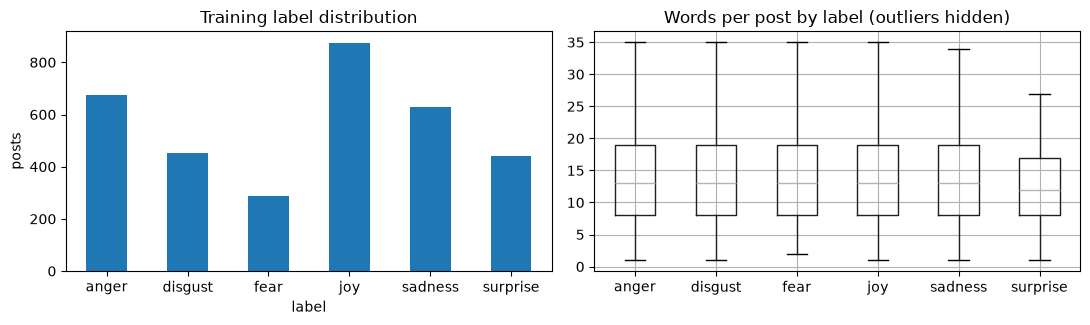

In [2]:
# Text length and source artefacts: placeholders such as [NAME] / @<username> show the
# posts come from several sources (Reddit-style and Twitter-style) that were anonymised.
train["n_words"] = train.text.str.split().str.len()
print(train.n_words.describe().round(1).to_dict())
for pat in [r"\[NAME\]", r"@<username>", r"http", r"&amp;|&gt;|&lt;"]:
    print(f"{pat:16s} share of posts: {train.text.str.contains(pat).mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
train.label.value_counts().reindex(LABELS).plot(kind="bar", ax=axes[0], color="tab:blue")
axes[0].set_title("Training label distribution"); axes[0].set_ylabel("posts"); axes[0].tick_params(axis="x", rotation=0)
train.boxplot(column="n_words", by="label", ax=axes[1], showfliers=False)
axes[1].set_title("Words per post by label (outliers hidden)"); axes[1].set_xlabel(""); plt.suptitle("")
plt.tight_layout(); plt.show()

In [3]:
# Cleaning. Two versions, because the two model families want different things:
#  - clean_for_transformer: keep casing, punctuation and emoji (they carry emotion signal);
#    only replace anonymisation placeholders with natural tokens and squeeze whitespace.
#  - clean_for_tfidf: additionally lower-case and decode HTML entities for the sparse baseline.
import html

def clean_for_transformer(t: str) -> str:
    t = t.replace("@<username>", "@user").replace("[NAME]", "Alex")
    return " ".join(t.split())

def clean_for_tfidf(t: str) -> str:
    t = html.unescape(clean_for_transformer(t)).lower()
    t = re.sub(r"http\S+", " url ", t)
    return " ".join(t.split())

train["clean"] = train.text.map(clean_for_tfidf); test["clean"] = test.text.map(clean_for_tfidf)
for t in train.text.head(3):
    print(repr(t), "->", repr(clean_for_transformer(t)))

'Thought it looked weird as well.' -> 'Thought it looked weird as well.'
'Bear died in a pit' -> 'Bear died in a pit'
'I have endured worse.' -> 'I have endured worse.'


## 2. Feature Engineering Steps

In [4]:
# ===== 2. Feature engineering (sparse baseline) =====
# Word 1-2 grams capture emotion words and short phrases ("so scared", "not happy");
# character 2-5 grams (within word boundaries) add robustness to misspellings,
# elongations ("sooo") and the machine-translated / non-standard spellings in the data.
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

word_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
X_train_sparse = hstack([word_vec.fit_transform(train.clean), char_vec.fit_transform(train.clean)]).tocsr()
X_test_sparse = hstack([word_vec.transform(test.clean), char_vec.transform(test.clean)]).tocsr()
y = train.label.map({l: i for i, l in enumerate(LABELS)}).to_numpy()
print("sparse features:", X_train_sparse.shape[1])

sparse features: 64659


In [5]:
# Transformer features are learned end-to-end: each model's own sub-word tokenizer
# (BPE for RoBERTa, SentencePiece for DeBERTa-v3) turns clean_for_transformer(text) into
# ids, truncated at 128 tokens (99%+ of posts are shorter), padded per batch.
# The emotion-pretrained checkpoints already know this label space: their output rows for
# anger/disgust/fear/joy/sadness/surprise are copied into the new 6-way head (see train.py).

## 3. Model Implementation Steps

### 3.1 Sparse baseline (reference)

In [6]:
# ===== 3. Models =====
# 3.1 Sparse baseline, 5-fold stratified CV (same folds as the transformers, seed 42).
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report

skf = StratifiedKFold(5, shuffle=True, random_state=42)
for name, clf in [("LogReg C=10", LogisticRegression(C=10, max_iter=3000, class_weight="balanced")),
                  ("LinearSVC C=0.5", LinearSVC(C=0.5, class_weight="balanced"))]:
    oof_pred = cross_val_predict(clf, X_train_sparse, y, cv=skf)
    print(f"{name:16s} CV macro F1 = {f1_score(y, oof_pred, average='macro'):.4f}")

LogReg C=10      CV macro F1 = 0.5009


LinearSVC C=0.5  CV macro F1 = 0.5141


### 3.2 Transformer fine-tuning (run on Kaggle, 2× T4 GPU)

The next cell is the training script exactly as it ran in the Kaggle notebook. It is written to disk here but **not executed in this notebook** (it needs a GPU and the Hugging Face hub). On Kaggle it was launched once per model, one queue per GPU; each run saved its out-of-fold and test probabilities, which are stored in `competition/oof/` so that the ensemble below can be re-run on a CPU.

In [7]:
%%writefile competition/train.py
"""5-fold fine-tuning of one transformer on the DM2026 Lab 2 emotion data.

Usage: python train.py MODEL_NAME TAG [lr] [epochs] [max_len] [batch]
Writes /kaggle/working/out/{TAG}_oof.npy, {TAG}_test.npy, {TAG}_log.json
"""
import json, os, sys, time, math, random
import numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_cosine_schedule_with_warmup

MODEL, TAG = sys.argv[1], sys.argv[2]
LR = float(sys.argv[3]) if len(sys.argv) > 3 else 1e-5
EPOCHS = int(sys.argv[4]) if len(sys.argv) > 4 else 4
MAX_LEN = int(sys.argv[5]) if len(sys.argv) > 5 else 128
BS = int(sys.argv[6]) if len(sys.argv) > 6 else 16
SEED, N_FOLDS = 42, 5
QUICK = bool(os.environ.get("QUICK"))   # smoke test: 1 fold, 1 epoch, 200 rows
if QUICK: EPOCHS = 1
LABELS = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]
import glob
DATA = os.environ.get("DATA_DIR") or os.path.dirname(
    sorted(glob.glob("/kaggle/input/**/final_posts.json", recursive=True))[0])   # competition mount point
OUT = "/kaggle/working/out"; os.makedirs(OUT, exist_ok=True)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

# ---------- data ----------
posts = pd.DataFrame(json.load(open(f"{DATA}/final_posts.json")))
ids = pd.read_csv(f"{DATA}/data_identification.csv")
lab = pd.read_csv(f"{DATA}/emotion.csv")
df = posts.merge(ids, on="post_id").merge(lab, on="post_id", how="left")
train = df[df.set == "train"].reset_index(drop=True)
test = df[df.set == "test"].reset_index(drop=True)
y = train.label.map({l: i for i, l in enumerate(LABELS)}).to_numpy()

def clean(t):
    # light normalisation only: transformers use casing/punctuation as signal
    t = t.replace("@<username>", "@user").replace("[NAME]", "Alex")
    return " ".join(t.split())

tok = AutoTokenizer.from_pretrained(MODEL)
def encode(texts):
    return tok([clean(t) for t in texts], truncation=True, max_length=MAX_LEN)

enc_train, enc_test = encode(train.text.tolist()), encode(test.text.tolist())

def make_loader(enc, idx, labels=None, shuffle=False):
    items = [{"input_ids": enc["input_ids"][i], "attention_mask": enc["attention_mask"][i],
              **({"labels": int(labels[i])} if labels is not None else {})} for i in idx]
    if not shuffle:  # sort by length for fast inference, remember order
        order = np.argsort([len(x["input_ids"]) for x in items])
        items = [items[i] for i in order]
    else:
        order = None
    def collate(b):
        out = tok.pad([{k: v for k, v in x.items() if k != "labels"} for x in b], return_tensors="pt")
        if "labels" in b[0]:
            out["labels"] = torch.tensor([x["labels"] for x in b])
        return out
    return DataLoader(items, batch_size=BS if shuffle else 64, shuffle=shuffle, collate_fn=collate), order

@torch.no_grad()
def predict(model, loader, order):
    model.eval(); outs = []
    for b in loader:
        b = {k: v.cuda() for k, v in b.items() if k != "labels"}
        with torch.autocast("cuda", dtype=torch.float16):
            outs.append(model(**b).logits.float().softmax(-1).cpu().numpy())
    p = np.concatenate(outs)
    res = np.empty_like(p); res[order] = p   # undo length sorting
    return res

def load_model():
    m = AutoModelForSequenceClassification.from_pretrained(
        MODEL, num_labels=len(LABELS), ignore_mismatched_sizes=True,
        id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)})
    # If the checkpoint was already an emotion classifier with these label names,
    # copy its output rows so fine-tuning starts from the pretrained head.
    try:
        src = AutoModelForSequenceClassification.from_pretrained(MODEL)
        names = {v.lower(): int(k) for k, v in src.config.id2label.items()}
        if all(l in names for l in LABELS):
            sw = dict(src.named_parameters()); dw = dict(m.named_parameters())
            for n, p in dw.items():
                if p.shape[0] == len(LABELS) and n in sw and sw[n].shape[0] == len(names):
                    p.data.copy_(sw[n].data[[names[l] for l in LABELS]])
            print("copied pretrained emotion head rows")
        del src
    except Exception as e:
        print("head copy skipped:", e)
    return m.float().cuda()   # some checkpoints (e.g. DeBERTa-v3) load in fp16; AMP needs fp32 master weights

oof = np.zeros((len(train), len(LABELS))); test_pred = np.zeros((len(test), len(LABELS)))
log = {"model": MODEL, "lr": LR, "epochs": EPOCHS, "max_len": MAX_LEN, "folds": []}
skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
test_loader, test_order = make_loader(enc_test, range(len(test)))
t_start = time.time()
for fold, (tr_idx, va_idx) in enumerate(skf.split(train, y)):
    if QUICK and fold > 0: break
    if QUICK: tr_idx = tr_idx[:200]
    seed_all(SEED + fold + 100 * int(os.environ.get("SEED_OFFSET", "0")))   # folds stay fixed; init/shuffle seed varies
    model = load_model()
    tr_loader, _ = make_loader(enc_train, tr_idx, y, shuffle=True)
    va_loader, va_order = make_loader(enc_train, va_idx, y)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    steps = EPOCHS * len(tr_loader)
    sch = get_cosine_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler()
    best = (-1, None, None)
    for ep in range(EPOCHS):
        model.train()
        for b in tr_loader:
            b = {k: v.cuda() for k, v in b.items()}
            with torch.autocast("cuda", dtype=torch.float16):
                loss = torch.nn.functional.cross_entropy(
                    model(input_ids=b["input_ids"], attention_mask=b["attention_mask"]).logits.float(),
                    b["labels"], label_smoothing=0.05)
            opt.zero_grad(); scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
        pv = predict(model, va_loader, va_order)
        f1 = f1_score(y[va_idx], pv.argmax(1), average="macro")
        print(f"[{TAG}] fold {fold} epoch {ep + 1} val macroF1 {f1:.4f} ({time.time() - t_start:.0f}s)", flush=True)
        if f1 > best[0]:
            best = (f1, pv, predict(model, test_loader, test_order))
    oof[va_idx] = best[1]; test_pred += best[2] / N_FOLDS
    log["folds"].append(best[0])
    del model, opt; torch.cuda.empty_cache()

log["oof_macro_f1"] = float(f1_score(y, oof.argmax(1), average="macro"))
log["seconds"] = round(time.time() - t_start)
print(f"[{TAG}] OOF macro F1 {log['oof_macro_f1']:.4f}", flush=True)
np.save(f"{OUT}/{TAG}_oof.npy", oof); np.save(f"{OUT}/{TAG}_test.npy", test_pred)
json.dump(log, open(f"{OUT}/{TAG}_log.json", "w"), indent=1)

Writing competition/train.py


In [8]:
# How the training script was launched on Kaggle (two GPUs, one queue per GPU).
# Run 1 and run 2 used the same 5-fold split (seed 42); SEED_OFFSET only changes the
# weight initialisation / shuffling seed. Shown for reproducibility; not executed here.
RUNS = [
    # (checkpoint, tag, lr, epochs, max_len, batch, seed_offset)
    ("j-hartmann/emotion-english-roberta-large", "jh_roberta_large", 1e-5, 4, 128, 16, 0),
    ("SamLowe/roberta-base-go_emotions", "goemo_roberta_base", 2e-5, 4, 128, 16, 0),
    ("cardiffnlp/twitter-roberta-large-2022-154m", "tw_roberta_large", 1e-5, 4, 128, 16, 0),
    ("roberta-large", "roberta_large", 1e-5, 4, 128, 16, 0),
    ("microsoft/deberta-v3-large", "deberta_v3_large", 8e-6, 5, 128, 16, 0),
    ("j-hartmann/emotion-english-roberta-large", "jh_roberta_large_s1", 8e-6, 3, 128, 16, 1),
    ("SamLowe/roberta-base-go_emotions", "goemo_roberta_base_s1", 2e-5, 4, 128, 16, 1),
    ("cardiffnlp/twitter-roberta-large-2022-154m", "tw_roberta_large_e6", 1e-5, 6, 128, 16, 0),
    ("roberta-large", "roberta_large_e6", 8e-6, 6, 128, 16, 0),
]
for m, t, lr, ep, ml, bs, so in RUNS:
    print(f"SEED_OFFSET={so} python competition/train.py {m} {t} {lr} {ep} {ml} {bs}")

SEED_OFFSET=0 python competition/train.py j-hartmann/emotion-english-roberta-large jh_roberta_large 1e-05 4 128 16
SEED_OFFSET=0 python competition/train.py SamLowe/roberta-base-go_emotions goemo_roberta_base 2e-05 4 128 16
SEED_OFFSET=0 python competition/train.py cardiffnlp/twitter-roberta-large-2022-154m tw_roberta_large 1e-05 4 128 16
SEED_OFFSET=0 python competition/train.py roberta-large roberta_large 1e-05 4 128 16
SEED_OFFSET=0 python competition/train.py microsoft/deberta-v3-large deberta_v3_large 8e-06 5 128 16
SEED_OFFSET=1 python competition/train.py j-hartmann/emotion-english-roberta-large jh_roberta_large_s1 8e-06 3 128 16
SEED_OFFSET=1 python competition/train.py SamLowe/roberta-base-go_emotions goemo_roberta_base_s1 2e-05 4 128 16
SEED_OFFSET=0 python competition/train.py cardiffnlp/twitter-roberta-large-2022-154m tw_roberta_large_e6 1e-05 6 128 16
SEED_OFFSET=0 python competition/train.py roberta-large roberta_large_e6 8e-06 6 128 16


### 3.3 Ensemble of the saved fold predictions and the submission file

In [9]:
# Every model's out-of-fold and test probabilities, as saved by train.py on Kaggle.
import glob, os
from sklearn.metrics import f1_score, confusion_matrix

OOF_DIR = "competition/oof"
oof = {os.path.basename(p)[:-8]: np.load(p) for p in sorted(glob.glob(f"{OOF_DIR}/*_oof.npy"))}
tst = {t: np.load(f"{OOF_DIR}/{t}_test.npy") for t in oof}
mf1 = lambda p: f1_score(y, p.argmax(1), average="macro")
print(pd.Series({t: round(mf1(p), 4) for t, p in oof.items()}).sort_values(ascending=False).to_string())

# Final ensemble: equal-weight average of both seeds of the two emotion-pretrained models.
FINAL = ["jh_roberta_large", "jh_roberta_large_s1", "goemo_roberta_base", "goemo_roberta_base_s1"]
oof_blend = sum(oof[t] for t in FINAL) / len(FINAL)
print(f"\nOOF macro F1 of the final blend: {mf1(oof_blend):.4f}")
print(classification_report(y, oof_blend.argmax(1), target_names=LABELS, digits=3))

# Robustness check: is the greedy-selected pair really better than the 4-model average?
greedy = (oof["jh_roberta_large_s1"] + oof["goemo_roberta_base_s1"]) / 2
rng = np.random.default_rng(0); diffs = []
for _ in range(400):
    i = rng.integers(0, len(y), len(y))
    diffs.append(f1_score(y[i], greedy[i].argmax(1), average="macro") - f1_score(y[i], oof_blend[i].argmax(1), average="macro"))
print(f"greedy pair - final blend: mean {np.mean(diffs):+.4f}, better in {np.mean(np.array(diffs) > 0):.0%} of 400 bootstrap samples")

# Submission file: the column names the scorer expects are id,label.
test_blend = sum(tst[t] for t in FINAL) / len(FINAL)
submission = pd.DataFrame({"id": test.post_id, "label": [LABELS[i] for i in test_blend.argmax(1)]})
submission.to_csv("competition/submission.csv", index=False)
print(submission.shape, submission.label.value_counts().to_dict())

jh_roberta_large_s1      0.6358
jh_roberta_large         0.6307
goemo_roberta_base       0.6282
goemo_roberta_base_s1    0.6255
tw_roberta_large_e6      0.6174
tw_roberta_large         0.6173
roberta_large_e6         0.6134
deberta_v3_large         0.5318
roberta_large            0.5267

OOF macro F1 of the final blend: 0.6479
              precision    recall  f1-score   support

       anger      0.600     0.680     0.637       674
     disgust      0.562     0.410     0.474       454
        fear      0.739     0.660     0.697       288
         joy      0.731     0.806     0.767       875
     sadness      0.672     0.691     0.681       628
    surprise      0.664     0.601     0.631       441

    accuracy                          0.666      3360
   macro avg      0.661     0.641     0.648      3360
weighted avg      0.663     0.666     0.661      3360



greedy pair - final blend: mean +0.0017, better in 74% of 400 bootstrap samples
(1440, 2) {'joy': 406, 'anger': 353, 'sadness': 257, 'surprise': 190, 'disgust': 121, 'fear': 113}
